In [ ]:
# Hosted D2L setup: fetch the exact helper module used to build this notebook.
from pathlib import Path
from urllib.request import urlretrieve
from importlib.metadata import PackageNotFoundError, version
import importlib.util, os, subprocess, sys

required = ['numpy', 'pandas', 'matplotlib', 'requests', 'scipy', 'pillow', 'regex', 'torch', 'torchvision']
imports = {'pillow': 'PIL'}
pinned = {}
fallbacks = {'torch': 'torch==2.11.0', 'torchvision': 'torchvision==0.26.0'}
device = os.environ.get("D2L_HOSTED_DEVICE", "auto").lower()
if device not in ("auto", "cpu", "gpu"):
    raise ValueError(f"Invalid D2L_HOSTED_DEVICE={device!r}")
if device == "auto":
    try:
        gpu = (Path("/dev/nvidia0").exists() or
               subprocess.run(["nvidia-smi", "-L"], capture_output=True,
                              timeout=5).returncode == 0)
    except (FileNotFoundError, subprocess.SubprocessError):
        gpu = False
else:
    gpu = device == "gpu"
if not gpu:
    os.environ.setdefault("CUDA_VISIBLE_DEVICES", "-1")
    os.environ.setdefault("JAX_PLATFORMS", "cpu")
tensorflow_version = None
if 'pytorch' in ("tensorflow", "jax"):
    try:
        tensorflow_version = version("tensorflow")
    except PackageNotFoundError:
        pass
# Colab's CPU image currently carries a CUDA-enabled TensorFlow wheel. Its
# first ordinary tensor operation probes CUDA and emits an error-level cuInit
# diagnostic. JAX notebooks also use TensorFlow for data loading, so overlay
# the matching CPU build in both CPU variants. Keep the provider's
# ``tensorflow`` distribution metadata: other preinstalled Colab packages
# depend on that distribution name, while both wheels expose the same module.
if not gpu and 'pytorch' in ("tensorflow", "jax"):
    try:
        tensorflow_cpu_version = version("tensorflow-cpu")
    except PackageNotFoundError:
        tensorflow_cpu_version = None
    if (tensorflow_version is not None and
            tensorflow_cpu_version != tensorflow_version):
        subprocess.check_call([
            sys.executable, "-m", "pip", "install", "-q", "--no-deps",
            f"tensorflow-cpu=={tensorflow_version}",
        ])
if "tf-keras" in fallbacks and tensorflow_version is not None:
    fallbacks["tf-keras"] = f"tf-keras=={tensorflow_version}"
missing = []
for package in required:
    if package in pinned:
        wanted, cpu_requirement, gpu_requirement, match = pinned[package]
        requirement = gpu_requirement if gpu else cpu_requirement
        if requirement is None:  # a GPU-only package on a CPU runtime
            continue
        try:
            installed = version(package)
        except PackageNotFoundError:
            installed = None
        actual = (installed.split("+", 1)[0]
                  if installed is not None and match == "public" else installed)
        if actual != wanted:
            missing.append(requirement)
    elif importlib.util.find_spec(imports.get(package, package)) is None:
        missing.append(fallbacks.get(package, package))
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])

mismatched = []
for package, (wanted, cpu_requirement, _, match) in pinned.items():
    if not gpu and cpu_requirement is None:
        continue
    try:
        installed = version(package)
    except PackageNotFoundError:
        installed = None
    actual = (installed.split("+", 1)[0]
              if installed is not None and match == "public" else installed)
    if actual != wanted:
        mismatched.append(f"{package}={installed!r} (expected {wanted})")
if mismatched:
    raise RuntimeError("Hosted runtime setup failed: " + ", ".join(mismatched))

root = Path(".d2l-hosted") / "46d487bb9b699b97c7c5fc5edd866e4d2ad7919b"
package = root / "d2l"
package.mkdir(parents=True, exist_ok=True)
base = "https://raw.githubusercontent.com/smolix/d2l-neu/46d487bb9b699b97c7c5fc5edd866e4d2ad7919b/d2l"
for name in ('__init__.py', 'torch.py'):
    target = package / name
    if not target.exists():
        urlretrieve(f"{base}/{name}", target)
if str(root.resolve()) not in sys.path:
    sys.path.insert(0, str(root.resolve()))
pythonpath = os.environ.get("PYTHONPATH", "").split(os.pathsep)
if str(root.resolve()) not in pythonpath:
    os.environ["PYTHONPATH"] = os.pathsep.join(
        [str(root.resolve()), *[entry for entry in pythonpath if entry]]
    )


# Generative Adversarial Networks

@Goodfellow.Pouget-Abadie.Mirza.ea.2014 introduced *generative adversarial networks* (GANs) by pairing a generator network with a binary classifier, called the *discriminator* or *critic*, that learns to distinguish real data from generated samples, much like the domain classifier used for covariate-shift correction in that section.

Two fundamental questions arise immediately:

1. If a generator fools the discriminator, has it actually learned to match the data distribution $p$?
2. When the discriminator can easily separate generated samples from real data, does its gradient still guide the generator toward $p$?

Because the optimal discriminator for a fixed generator can be derived in closed form, we can answer both questions analytically. We then verify our analysis on a 2D Gaussian problem where exact densities and KL divergences are available in closed form, and finally train a multilayer perceptron generator on Fashion-MNIST images.

In [1]:
import math
import numpy as np
import torch
from torch import nn
from torch.nn import functional as F
from d2l import torch as d2l

## From Likelihood to Two-Sample Comparison

### Implicit Generators

Maximum likelihood estimation requires evaluating the model's log-density $\log p_\theta(x)$ at each observation. By contrast, the generators in this chapter are *implicit*: they sample a latent vector $z \sim \mathcal{N}(0, I_{d_z})$ and pass it through a deterministic network $x' = G(z)$. When the latent dimension $d_z$ is smaller than the data dimension $d_x$, generated samples lie on a low-dimensional manifold and do not admit a density with respect to Lebesgue measure on $\mathbb{R}^{d_x}$. Even when $d_z = d_x$, computing the induced density via the change-of-variables formula requires $G$ to be invertible with a tractable Jacobian determinant.

Moreover, high test log-likelihood does not guarantee realistic samples [@Theis.Oord.Bethge.2016]. Consider a mixture of the true data distribution with uniform or Gaussian noise:

$$
\tilde p \;=\; 0.01\, p_{\textrm{data}} + 0.99\, p_{\textrm{noise}}.
$$

Because $\tilde p(x) \geq 0.01\, p_{\textrm{data}}(x)$ everywhere, its expected log-likelihood falls short of the true data distribution by at most $\log 100 \approx 4.6$ nats—a negligible difference for images, whose log-likelihoods span thousands of nats. Yet 99% of samples drawn from $\tilde p$ are pure noise. Evaluating a sample generator therefore requires inspecting its samples directly.

### Discriminating Real from Generated Samples

A *two-sample test* checks whether two sets of samples come from the same distribution, and a natural way to implement one is to train a binary classifier to separate them. A GAN uses this classifier to provide gradients to the generator. Let $y \sim \textrm{Bernoulli}(\tfrac12)$ be a balanced source label: if $y = 1$, we draw $x \sim p$ from the data distribution; if $y = 0$, we draw $x \sim q$ from the generator distribution. The marginal distribution of $x$ is the balanced mixture $m = (p + q)/2$.

The *critic* (or *discriminator*) is a function $D: \mathcal{X} \to \mathbb{R}$ that outputs a *realness logit*, so that $\sigma(D(x)) = 1/(1 + e^{-D(x)})$ estimates the posterior probability $P(y = 1 \mid x)$. Following @Goodfellow.Pouget-Abadie.Mirza.ea.2014, our code uses `net_D` and `update_D` for the discriminator network, while the text also uses the term *critic* to encompass non-probabilistic scoring networks later in the chapter. (Note that a GAN critic is distinct from the value-function critic in actor–critic reinforcement learning, that section.)

As shown in the figure, training alternates between the two networks: the discriminator is updated to separate real minibatches from generated minibatches, and the generator is updated via gradients backpropagated through the discriminator to make its samples harder to classify as fake.

![Adversarial training. The generator $G$ maps latent draws $z$ to generated samples, and the critic $D$ scores both generated and real samples. The critic maximizes its score on real data and minimizes it on generated samples, while the generator uses gradients through $D$ to make the two distributions indistinguishable.](https://raw.githubusercontent.com/smolix/d2l-neu/notebooks/img/mdl-gan-architecture.svg)

## The Log-Loss Objective

Training the discriminator by binary cross-entropy (log loss) on balanced real and generated samples yields the minimax value function of @Goodfellow.Pouget-Abadie.Mirza.ea.2014:

$$
V(D) \;=\; \mathbb{E}_{x \sim p}\big[\log \sigma(D(x))\big] + \mathbb{E}_{x' \sim q}\big[\log \sigma(-D(x'))\big].
$$

The discriminator maximizes $V(D)$, while the generator affects only the second term and seeks to minimize $V(D)$, resulting in the minimax problem $\min_G \max_D V(D)$.

### The Optimal Critic

For a fixed generator distribution $q$, maximizing the equation decouples pointwise across $x$. At each point $x$, the integrand is $p(x) \log \sigma(D(x)) + q(x) \log \sigma(-D(x))$. Writing $u = \sigma(D(x)) \in (0, 1)$, maximizing the strictly concave function $p \log u + q \log(1-u)$ via the first-order condition $p/u = q/(1-u)$ gives the unique optimum:

$$
\begin{aligned}
\sigma(D^\star(x)) &= \frac{p(x)}{p(x) + q(x)} = P(y = 1 \mid x), \\
D^\star(x) &= \log \frac{p(x)}{q(x)} = \lambda(x).
\end{aligned}
$$

Thus, the optimal discriminator outputs the Bayes posterior $P(y = 1 \mid x)$, and its logit $D^\star(x)$ equals the *log density ratio* $\lambda(x) = \log \rho(x)$, where $\rho(x) = p(x)/q(x)$. Even though $q(x)$ has no closed-form density, binary classification estimates $\log(p/q)$ directly from samples. Furthermore, the log-loss objective uniquely pins down the additive constant of $D^\star$: shifting $D^\star$ by any nonzero constant $b$ strictly decreases $V$ (Exercise 1), so $D^\star(x) > 0$ precisely where $p(x) > q(x)$.

For example, for two unit-variance Gaussians $p = \mathcal{N}(0, 1)$ and $q = \mathcal{N}(\mu, 1)$, the optimal logit is affine in $x$:

$$
\lambda(x) = -\frac{x^2}{2} + \frac{(x - \mu)^2}{2} = \mu \Big(\frac{\mu}{2} - x\Big),
$$

which changes sign at the midpoint $\mu/2$. When $p$ and $q$ have different covariance matrices, $\lambda(x)$ is quadratic in $x$ and requires a nonlinear discriminator.

### Connection to Jensen–Shannon Divergence

Substituting the optimal discriminator $\sigma(D^\star) = p/(2m)$ and $\sigma(-D^\star) = q/(2m)$ back into the equation reveals what the generator minimizes against an optimal discriminator:

$$
\begin{aligned}
V(D^\star) &= \int p \log \frac{p}{2m} + \int q \log \frac{q}{2m} \\
&= D_{\textrm{KL}}(p \,\|\, m) + D_{\textrm{KL}}(q \,\|\, m) - 2 \log 2 .
\end{aligned}
$$

Using the definition of the Jensen–Shannon divergence, $\mathrm{JS}(p, q) = \tfrac12 D_{\textrm{KL}}(p \,\|\, m) + \tfrac12 D_{\textrm{KL}}(q \,\|\, m)$, we obtain:

$$
\max_D V(D) = 2\,\mathrm{JS}(p, q) - 2 \log 2 .
$$

Because $\mathrm{JS}(p, q) \geq 0$ with equality if and only if $q = p$, minimizing $\max_D V(D)$ uniquely recovers the data distribution $q = p$ at the global minimum $-2\log 2$ (where $D^\star(x) = 0$ everywhere and the discriminator is reduced to random guessing).

Expanding $D_{\textrm{KL}}(p \,\|\, m)$ and $D_{\textrm{KL}}(q \,\|\, m)$ in terms of differential entropies provides an information-theoretic interpretation:

$$
\mathrm{JS}(p, q) \;=\; H(m) - \frac{H(p) + H(q)}{2} \;=\; I(x; y).
$$

That is, $\mathrm{JS}(p, q)$ equals the mutual information $I(x; y)$ between a sample $x \sim m$ and its binary source label $y$. Because a binary label carries at most $\log 2$ nats of information, $0 \leq \mathrm{JS}(p, q) \leq \log 2$, reaching $\log 2$ whenever $p$ and $q$ have disjoint supports.

### Disjoint Supports and Vanishing Gradients

Because $\mathrm{JS}(p, q)$ saturates at $\log 2$, the minimax objective becomes constant whenever the supports of $p$ and $q$ do not overlap. For instance, if $p = \delta_0$ and $q_\theta = \delta_\theta$ are point masses on $\mathbb{R}$, then $\mathrm{JS}(p, q_\theta) = \log 2$ for every $\theta \neq 0$, yielding zero gradient with respect to $\theta$ no matter how close $\theta$ is to $0$. Even when supports overlap in their tails, as for $p = \mathcal{N}(0, 1)$ and $q = \mathcal{N}(\mu, 1)$, $\mathrm{JS}(p, q)$ equals $0.11$, $0.34$, and $0.63$ nats at $\mu = 1, 2, 4$, and at $\mu = 8$ it lies within $10^{-4}$ of $\log 2 \approx 0.6931$. the figure shows the whole curve: it is flat long before the two Gaussians stop overlapping in any formal sense.

![The Jensen–Shannon divergence between $p = \mathcal{N}(0, 1)$ and $q = \mathcal{N}(\mu, 1)$ as a function of the shift $\mu$. The divergence reaches its ceiling $\log 2$ within a few standard deviations. Beyond that the curve is flat, and a flat curve gives the generator no gradient.](https://raw.githubusercontent.com/smolix/d2l-neu/notebooks/img/mdl-gan-js-saturation.svg)

In high dimensions, disjoint supports are the norm rather than the exception: both natural images and the outputs of a generator $G: \mathbb{R}^{d_z} \to \mathbb{R}^{d_x}$ with $d_z \ll d_x$ concentrate on low-dimensional manifolds whose intersection typically has measure zero [@Arjovsky.Bottou.2017]. When the discriminator separates them perfectly, the minimax value saturates.

The most direct remedy is to make the supports overlap. Suppose we add independent Gaussian noise of scale $s$ to every real and every generated sample before the discriminator sees it. The discriminator then compares two smoothed densities, which are positive everywhere. For the point masses above they are $\mathcal{N}(0, s^2)$ and $\mathcal{N}(\theta, s^2)$, and their divergence is the curve of the figure read at $\mu = \theta/s$: the generator receives a gradient as long as $\theta$ lies within a few multiples of $s$. This is *instance noise* [@Sonderby.Caballero.Theis.ea.2017; @Arjovsky.Bottou.2017]. Unfortunately the generator now matches the blurred data rather than the data, so $s$ has to be annealed toward zero during training. The idea returns in that section, where the samples are noised by a diffusion model.

## The Generator's Gradient

In practice, the generator takes gradient steps against a fixed discriminator $D$ rather than minimizing $\max_D V(D)$ directly. Let us examine the gradient of the generator objective.

### Saturating versus Non-Saturating Weights

In the literal minimax formulation, the generator minimizes $\mathbb{E}_z[\log \sigma(-D(G(z)))]$ with respect to its parameters $\theta$. Using $\tfrac{d}{du} \log \sigma(-u) = -\sigma(u)$ and $x' = G(z)$, the gradient is:

$$
\begin{aligned}
&\nabla_\theta \, \mathbb{E}_z\big[\log \sigma(-D(G(z)))\big] \\
&\qquad = -\,\mathbb{E}_z\big[\sigma(D(x'))\, \nabla_\theta D(G(z))\big].
\end{aligned}
$$

Each generated sample $x'$ is pushed uphill along $\nabla_\theta D(G(z))$, weighted by $\sigma(D(x'))$—the discriminator's estimated probability that $x'$ is real. When the discriminator confidently rejects a sample ($D(x') \ll 0$), this weight $\sigma(D(x')) \approx e^{D(x')}$ becomes exponentially small, causing the generator gradient to *saturate* precisely when the generator most needs to improve.

To avoid this saturation, @Goodfellow.Pouget-Abadie.Mirza.ea.2014 trained the generator to maximize the log-probability of its samples being classified as real, minimizing $-\mathbb{E}_z[\log \sigma(D(G(z)))]$. Since $\tfrac{d}{du} \log \sigma(u) = \sigma(-u)$, its gradient is:

$$
\begin{aligned}
&\nabla_\theta \Big({-\mathbb{E}_z\big[\log \sigma(D(G(z)))\big]}\Big) \\
&\qquad = -\,\mathbb{E}_z\big[\sigma(-D(x'))\, \nabla_\theta D(G(z))\big].
\end{aligned}
$$

Both objectives push each sample in the same direction $\nabla_\theta D(G(z))$, differing only in the per-sample scalar weight:

$$
\begin{aligned}
w_{\textrm{sat}}(x') &= \sigma(D(x')), \\
w_{\textrm{ns}}(x') &= \sigma(-D(x')) = 1 - \sigma(D(x')).
\end{aligned}
$$

As shown in the figure, the *non-saturating* weight $w_{\textrm{ns}}(x')$ approaches $1$ for confidently rejected samples ($D(x') \ll 0$), whereas $w_{\textrm{sat}}(x')$ decays as $e^{D(x')}$ (a ratio of $w_{\textrm{ns}}/w_{\textrm{sat}} = e^{-D(x')}$, or $20\times$ at $D = -3$ and $148\times$ at $D = -5$).

![Per-sample generator gradient weights as a function of the discriminator logit $D(x')$ on a log scale. For confidently rejected samples ($D(x') \ll 0$), the saturating weight $\sigma(D)$ decays exponentially, whereas the non-saturating weight $\sigma(-D)$ remains near 1.](https://raw.githubusercontent.com/smolix/d2l-neu/notebooks/img/mdl-gan-weights.svg)

### Effective Divergence of the Non-Saturating Loss

What divergence does the non-saturating generator loss descend when the discriminator is held at its optimal response $D = \lambda = \log(p/q)$? Using $\log \sigma(-D) - \log \sigma(D) = -D$, we can decompose the non-saturating objective as:

$$
\begin{aligned}
&-\mathbb{E}_{x'}\big[\log \sigma(D(x'))\big] \\
&\qquad = \mathbb{E}_{x'}\big[-D(x')\big] - \mathbb{E}_{x'}\big[\log \sigma(-D(x'))\big].
\end{aligned}
$$

With $D$ fixed at $\lambda$, the first term on the right has the same gradient with respect to $q$ as the reverse KL divergence $D_{\textrm{KL}}(q \,\|\, p) = \mathbb{E}_q[\log(q/p)]$, while the second term is minus the minimax loss, whose gradient is by the envelope theorem that of $2\,\mathrm{JS}(p, q) = D_{\textrm{KL}}(p \,\|\, m) + D_{\textrm{KL}}(q \,\|\, m)$ [@Arjovsky.Bottou.2017] (Exercise 5). Combining the integrals using $\log(q/p) - \log(q/m) = \log(m/p)$ and $p + q = 2m$ yields:

$$
\begin{aligned}
&D_{\textrm{KL}}(q \,\|\, p) - D_{\textrm{KL}}(p \,\|\, m) - D_{\textrm{KL}}(q \,\|\, m) \\
&\qquad = \int q \log \frac{m}{p} + \int p \log \frac{m}{p} \\
&\qquad = \int (p + q) \log \frac{m}{p} \;=\; 2\, D_{\textrm{KL}}(m \,\|\, p).
\end{aligned}
$$

Thus, against an optimal critic, the non-saturating generator descends $2\,D_{\textrm{KL}}(m \,\|\, p)$, the *softened reverse KL divergence* [@Shannon.Poole.Mariooryad.ea.2020], which shares the unique global minimum $q = p$.

Inspecting $2\,D_{\textrm{KL}}(m \,\|\, p)$ reveals an asymmetry in how errors are penalized:

- Where $q(x) > 0$ but $p(x) = 0$ (spurious samples outside the data support), $m(x) > 0 = p(x)$ and $D_{\textrm{KL}}(m \,\|\, p) = \infty$, heavily penalizing unrealistic samples.
- Where $p(x) > 0$ but $q(x) = 0$ (dropped modes of the data), $m(x) = p(x)/2$ and the integrand contributes only $p(x) \log \tfrac12$, a small finite penalty.

### Mode Dropping

When a generator covers only a subset of the modes of a multimodal distribution $p$, it exhibits *mode dropping* (or *mode collapse*). Suppose $p$ is an equal mixture of two disjoint modes and $q$ matches one mode perfectly while omitting the other. On the covered mode, $p = q/2$, so $D_{\textrm{KL}}(q \,\|\, p) = \log 2 \approx 0.69$ nats, $\mathrm{JS}(p, q) \approx 0.22$ nats, and $2\,D_{\textrm{KL}}(m \,\|\, p) \approx 0.26$ nats. Dropping half of the data distribution costs only a quarter of a nat. By contrast, maximum likelihood minimizes the forward KL divergence $D_{\textrm{KL}}(p \,\|\, q)$, which is infinite whenever any part of $p$ is assigned zero density.

Worse still, at the optimal discriminator response $D^\star(x) = \log(p(x)/q(x)) = -\log 2$ on the covered mode, $D^\star$ is constant across the support of $q$, so $\nabla_\theta D^\star(G(z)) = 0$: the local gradient on the covered mode vanishes and provides no signal pointing toward the missing mode. Even with an imperfect discriminator that assigns, say, $D = 3$ to generated samples on the covered mode and $D = 5$ to real samples on the uncovered mode, each generated sample is weighted only against the fixed zero threshold via $\sigma(-3) \approx 0.05$, and the higher scores on the uncovered real mode never enter the generator update. that section examines whether comparing generated scores directly against real scores helps address this.

## Verifying the Theory on a 2D Gaussian

To test the theoretical predictions quantitatively, we first train a linear generator on 2D Gaussian data, where $p$, $q$, $\lambda(x) = \log(p(x)/q(x))$, and $D_{\textrm{KL}}(q \,\|\, p)$ can all be computed in closed form.

### Alternating Update Rules

We define `update_D`, `update_G`, and the alternating training loop `train_gan` once and save them to `d2l` for reuse across the chapter. First, `update_D` performs one discriminator step maximizing the equation (minimizing binary cross-entropy with label $1$ for real samples and $0$ for detached generated samples). Dividing the summed loss by the batch size estimates $-V(D)$, which equals $2\log 2 \approx 1.386$ when $D = 0$.

In [ ]:

def update_D(X, Z, net_D, net_G, trainer_D):
    """Update the critic; return its log loss summed over both batches
    (per sample, the sum of two means: 2 log 2 at equilibrium)."""
    trainer_D.zero_grad()
    real_Y = net_D(X)
    # The generator is the fixed player here: detach its output
    fake_Y = net_D(net_G(Z).detach())
    loss_D = (F.binary_cross_entropy_with_logits(
                  real_Y, torch.ones_like(real_Y), reduction='sum') +
              F.binary_cross_entropy_with_logits(
                  fake_Y, torch.zeros_like(fake_Y), reduction='sum'))
    loss_D.backward()
    trainer_D.step()
    return loss_D

Next, `update_G` performs one generator step minimizing the non-saturating loss $-\mathbb{E}[\log \sigma(D(G(z)))]$, implemented as binary cross-entropy on the recomputed discriminator scores `net_D(net_G(Z))` with target label $1$, which equals $\log 2 \approx 0.693$ per sample when $D = 0$:

In [ ]:

def update_G(Z, net_D, net_G, trainer_G):
    """Update the generator on the non-saturating loss; return its sum."""
    trainer_G.zero_grad()
    # net_D changed in its half-step, so recompute the scores
    fake_Y = net_D(net_G(Z))
    loss_G = F.binary_cross_entropy_with_logits(
        fake_Y, torch.ones_like(fake_Y), reduction='sum')
    loss_G.backward()  # also fills net_D's .grad (update_D zeroes it)
    trainer_G.step()
    return loss_G

`train_gan` alternates `update_D` and `step_G` across minibatches using Adam with $\beta_1 = 0.5$ [@Radford.Metz.Chintala.2015] so that momentum adapts quickly to the changing objective. It also supports an optional per-epoch callback `on_epoch` and exponential moving average `ema`.

In [ ]:

def train_gan(net_D, net_G, data_iter, num_epochs, latent_dim, lr_D, lr_G,
              step_G=update_G, seed=None, on_epoch=None, ema=None):
    """Alternate update_D and step_G over the minibatches with Adam
    (beta_1 = 0.5), calling ema.update(net_G) after every generator step
    and on_epoch(epoch) after each epoch if given; return each epoch's
    per-sample losses (loss_D, the sum of the critic's two batch means,
    and loss_G)."""
    if seed is not None:
        torch.manual_seed(seed)
    trainer_D = torch.optim.Adam(net_D.parameters(), lr=lr_D,
                                 betas=(0.5, 0.999))
    trainer_G = torch.optim.Adam(net_G.parameters(), lr=lr_G,
                                 betas=(0.5, 0.999))
    history = []
    for epoch in range(1, num_epochs + 1):
        loss_D, loss_G, n = 0, 0, 0  # summed on the device, read once
        for X, *_ in data_iter:  # labels, if any, are ignored
            Z = torch.randn(X.shape[0], latent_dim, device=X.device)
            loss_D += update_D(X, Z, net_D, net_G, trainer_D).detach()
            loss_G += step_G(Z, net_D, net_G, trainer_G).detach()
            if ema is not None:
                ema.update(net_G)
            n += X.shape[0]
        history.append(torch.stack([loss_D, loss_G]) / n)
        if on_epoch is not None:
            on_epoch(epoch)
    return torch.stack(history).cpu().numpy()

### A Linear Generator with Known Densities

We generate 1,000 training points from $x = z A + b$ with $z \sim \mathcal{N}(0, I_2)$, so that the true data distribution is the tilted elliptical Gaussian $p = \mathcal{N}(b, A^\top A)$.

In [10]:
torch.manual_seed(0)
Z = torch.normal(0.0, 1.0, (1000, 2))
A = torch.tensor([[1.0, 2.0], [-0.1, 0.5]])
b = torch.tensor([1.0, 2.0])
data = Z @ A + b
print(f'covariance of the data distribution:\n{A.T @ A}')

covariance of the data distribution:
tensor([[1.0100, 1.9500],
        [1.9500, 4.2500]])


The generator is a single linear layer $G(z) = z A_q + \mu_q$, which induces the Gaussian distribution $q = \mathcal{N}(\mu_q, A_q^\top A_q)$. Because the log density ratio between two Gaussians with different covariances is quadratic, the discriminator uses a 3-layer MLP with two hidden layers of 16 leaky ReLU units (negative slope $0.2$; Exercise 3 examines what happens when saturating $\tanh$ activations are used instead).

In [11]:
def make_nets(seed=7):
    """The linear generator and the critic, all weights and offsets drawn
    from N(0, 0.02^2) by a generator seeded with seed."""
    gen = torch.Generator().manual_seed(seed)
    net_G = nn.Sequential(nn.Linear(2, 2))
    net_D = nn.Sequential(nn.Linear(2, 16), nn.LeakyReLU(0.2),
                          nn.Linear(16, 16), nn.LeakyReLU(0.2),
                          nn.Linear(16, 1))
    for w in [*net_G.parameters(), *net_D.parameters()]:
        nn.init.normal_(w, 0, 0.02, generator=gen)
    return net_G, net_D

We train for 20 epochs with batch size 8, setting `lr_D=0.05` and `lr_G=0.005` so the discriminator tracks its optimal response as the generator moves.

In [12]:
data_iter = d2l.load_array((data,), batch_size=8)
net_G, net_D = make_nets()
history = train_gan(net_D, net_G, data_iter, num_epochs=20, latent_dim=2,
                    lr_D=0.05, lr_G=0.005, seed=1)
with torch.no_grad():
    fake = net_G(torch.normal(0, 1, (200, 2)))

We now plot the per-epoch critic and generator losses in `history` against
their theoretical equilibrium values ($2\log 2$ and $\log 2$) alongside a
scatter plot of real (`data`) and generated (`fake`) samples:

In [ ]:
fig, axes = d2l.plt.subplots(1, 2, figsize=(9, 3.2))
epochs = list(range(1, len(history) + 1))
d2l.plot(epochs, [history[:, 0], history[:, 1], [2 * math.log(2)] * len(epochs),
                  [math.log(2)] * len(epochs)],
         'epoch', 'loss',
         legend=['critic', 'generator', '2 log 2', 'log 2'],
         fmts=('C0-', 'C1--', 'C0:', 'C1:'), axes=axes[0])
d2l.plot([data[:100, 0], fake[:100, 0]], [data[:100, 1], fake[:100, 1]],
         legend=['real', 'generated'], fmts=('C0.', 'C1.'), axes=axes[1])
fig.tight_layout()

Within 10 epochs, the discriminator loss rises to the equilibrium value $2\log 2$, the generator loss settles to $\log 2$, and the generated point cloud matches the target ellipse.

### Quantifying the Fit in Nats

Because $G(z) = z A_q + \mu_q$ defines a Gaussian $q = \mathcal{N}(\mu_q, \Sigma_q)$ with $\Sigma_q = A_q^\top A_q$, we can evaluate the exact KL divergence $D_{\textrm{KL}}(q \,\|\, p)$ in $d_x$ dimensions [@Kullback.1959]:

$$
\begin{aligned}
&D_{\textrm{KL}}\big(\mathcal{N}(\mu_0, \Sigma_0) \,\|\, \mathcal{N}(\mu_1, \Sigma_1)\big) \\
&\qquad = \tfrac12 \Big[ \operatorname{tr}(\Sigma_1^{-1} \Sigma_0)
+ (\mu_1 - \mu_0)^\top \Sigma_1^{-1} (\mu_1 - \mu_0) \\
&\qquad\qquad - d_x + \log \tfrac{\det \Sigma_1}{\det \Sigma_0} \Big].
\end{aligned}
$$

In [14]:
def generator_gaussian(net_G):
    A_qT, b_q = net_G[0].weight.detach(), net_G[0].bias.detach()
    return b_q, A_qT @ A_qT.T  # nn.Linear stores A_q.T

def kl_gaussians(mu0, S0, mu1, S1):
    diff = mu1 - mu0
    return 0.5 * (torch.trace(torch.linalg.solve(S1, S0))
                  + diff @ torch.linalg.solve(S1, diff) - len(mu0)
                  + torch.logdet(S1) - torch.logdet(S0))

mu_p, Sigma_p = b, A.T @ A
for name, net in [('at initialization', make_nets()[0]),
                  ('after training   ', net_G)]:
    mu_q, Sigma_q = generator_gaussian(net)
    print(f'KL(q || p) {name}: '
          f'{kl_gaussians(mu_q, Sigma_q, mu_p, Sigma_p):.3f} nats')

KL(q || p) at initialization: 7.501 nats
KL(q || p) after training   : 0.010 nats


Without ever evaluating the density of $q$, adversarial training reduces $D_{\textrm{KL}}(q \,\|\, p)$ from $\sim 8$ nats at initialization (dominated by the low entropy of the initial $\mathcal{N}(0, 0.02^2)$ weights) to a few hundredths of a nat.

### Verifying the Learned Log Density Ratio

To test whether a trained discriminator accurately recovers $\lambda(x) = \log(p(x)/q(x))$ (the equation), we fix a generator $q$ with $A_q = [[1, 2], [-0.5, 0.5]]$ and $\mu_q = (1.5, 1.5)$ ($D_{\textrm{KL}}(q \,\|\, p) \approx 3.4$ nats) and train a fresh discriminator against this frozen $q$ for 2,000 steps.

In [15]:
net_G_q, net_D_q = make_nets()  # a fresh critic
with torch.no_grad():  # the hand-set generator; nn.Linear stores A_q.T
    net_G_q[0].weight.copy_(torch.tensor([[1.0, -0.5], [2.0, 0.5]]))
    net_G_q[0].bias.copy_(torch.tensor([1.5, 1.5]))
trainer_D = torch.optim.Adam(net_D_q.parameters(), lr=0.01)
torch.manual_seed(2)
for _ in range(2000):  # critic-only steps against the frozen generator
    X = data[torch.randint(0, len(data), (256,))]
    Zb = torch.normal(0, 1, (256, 2))
    update_D(X, Zb, net_D_q, net_G_q, trainer_D)

We evaluate both the discriminator logit $D(x)$ and the exact log density ratio $\lambda(x)$ across 200 real and 200 generated points, reporting their correlation and explained variance $R^2$.

In [16]:
def gaussian_logpdf(x, mu, Sigma):
    diff = x - mu
    sol = torch.linalg.solve(Sigma, diff.T).T
    return -0.5 * ((diff * sol).sum(1)
                   + torch.logdet(2 * torch.pi * Sigma))

mu_q, Sigma_q = generator_gaussian(net_G_q)
with torch.no_grad():
    xs = torch.cat([data[:200], net_G_q(torch.normal(0, 1, (200, 2)))])
    lam = (gaussian_logpdf(xs, b, A.T @ A)
           - gaussian_logpdf(xs, mu_q, Sigma_q))
    D_out = net_D_q(xs).squeeze()
r2 = 1 - ((D_out - lam) ** 2).mean() / ((lam - lam.mean()) ** 2).mean()
print(f'correlation {torch.corrcoef(torch.stack([lam, D_out]))[0, 1]:.3f}, '
      f'R^2 {r2:.3f}')

correlation 0.981, R^2 0.962


Plotting the critic logits `D_out` against the exact log density ratio `lam`
across the 200 real and 200 generated samples visualizes how closely $D(x)$
tracks the identity line $D = \lambda$:

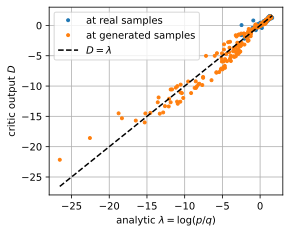

In [17]:
lims = [float(lam.min()), float(lam.max())]
d2l.plot([lam[:200], lam[200:], lims], [D_out[:200], D_out[200:], lims],
         r'analytic $\lambda = \log(p/q)$', 'critic output $D$',
         legend=['at real samples', 'at generated samples', r'$D = \lambda$'],
         fmts=('C0.', 'C1.', 'k--'), figsize=(4.2, 3.4))

The learned logits closely track the true log density ratio ($\text{correlation} \approx 0.98$, $R^2 > 0.90$). Deviations appear only at extreme negative values of $\lambda$ (generated samples where $p(x) \approx 0$): the piecewise-linear leaky-ReLU network extrapolates linearly rather than quadratically into the tails, and because $\tfrac{d}{dD}[-\log \sigma(-D)] = \sigma(D) \ll 1$ when $D \ll 0$, the log loss exerts almost no gradient to steepen the discriminator further once it is already confident.

### Saturating versus Non-Saturating Generator Loss

To compare the saturating and non-saturating weights (the equation) when the generator starts far from the data, we shift the initial generator bias by $(-6, 6)$ ($\sim 8$ units from the data mean, $D_{\textrm{KL}}(q \,\|\, p) \approx 345$ nats) and compare `update_G` against `update_G_saturating`, which minimizes $\mathbb{E}_z[\log \sigma(-D(G(z)))]$ directly.

In [18]:
def update_G_saturating(Z, net_D, net_G, trainer_G):
    trainer_G.zero_grad()
    fake_Y = net_D(net_G(Z))
    # log sigma(-D) is minus the cross-entropy under the label zero
    loss_G = -F.binary_cross_entropy_with_logits(
        fake_Y, torch.zeros_like(fake_Y), reduction='sum')
    loss_G.backward()
    trainer_G.step()
    return loss_G

We run three seeds for each generator objective from identical initializations and minibatches (`lr_G=0.01`, `lr_D=0.05`).

In [ ]:
def far_start():
    """make_nets with the generator's offset moved by (-6, 6)."""
    net_G, net_D = make_nets()
    with torch.no_grad():
        net_G[0].bias += torch.tensor([-6.0, 6.0])
    return net_G, net_D

mu_q, Sigma_q = generator_gaussian(far_start()[0])
print(f'start of every run: KL(q || p) = '
      f'{kl_gaussians(mu_q, Sigma_q, mu_p, Sigma_p):.2f} nats')
torch.manual_seed(3)
Z_show = torch.randn(200, 2)  # one latent sample for every snapshot
runs = {}  # name: (losses, snapshots) of the first run, for the plot
for name, step in [('non-saturating', update_G),
                   ('saturating', update_G_saturating)]:
    kls = []
    for seed in (1, 2, 3):  # both arms see the same minibatches and draws
        net_G_ab, net_D_ab = far_start()
        snaps = {}  # epoch: generated samples
        hist = train_gan(net_D_ab, net_G_ab, data_iter, num_epochs=20,
                         latent_dim=2, lr_D=0.05, lr_G=0.01, step_G=step,
                         seed=seed, on_epoch=lambda epoch: snaps.update(
                             {epoch: net_G_ab(Z_show).detach()}))
        runs.setdefault(name, (hist, snaps))
        mu_q, Sigma_q = generator_gaussian(net_G_ab)
        kls.append(f'{kl_gaussians(mu_q, Sigma_q, mu_p, Sigma_p):.2f}')
    print(f'{name}: final KL(q || p) = {", ".join(kls)} nats')

To see why the final KL divergences differ so starkly, we plot the generated
point clouds `snaps` at epochs 5 and 20 for each objective alongside their
critic loss trajectories:

In [ ]:
fig, axes = d2l.plt.subplots(1, 3, figsize=(10.5, 3.2))
for ax, (name, (hist, snaps)) in zip(axes[:2], runs.items()):
    d2l.plot([data[:150, 0], snaps[5][:, 0], snaps[20][:, 0]],
             [data[:150, 1], snaps[5][:, 1], snaps[20][:, 1]],
             legend=['real', 'epoch 5', 'epoch 20'],
             fmts=('C0.', 'C1+', 'C1.'), axes=ax)
    ax.set_title(name)
epochs = list(range(1, 21))
d2l.plot(epochs, [runs['non-saturating'][0][:, 0],
                  runs['saturating'][0][:, 0], [2 * math.log(2)] * 20],
         'epoch', 'critic loss', legend=['non-saturating', 'saturating',
                                         '2 log 2'],
         fmts=('-', '--', 'k:'), axes=axes[2])
fig.tight_layout()

In the first two epochs, both discriminators easily separate the distant generated points from the data, driving the discriminator loss near zero and $D(x') \ll 0$. Because $w_{\textrm{sat}}(x') = \sigma(D(x')) \approx 0$, the saturating generator stalls completely (still $335\text{--}340$ nats from the data after 20 epochs). By contrast, the non-saturating weight $w_{\textrm{ns}}(x') = \sigma(-D(x')) \approx 1$ preserves the discriminator's spatial gradient $\nabla_\theta D(G(z))$, pulling the generator onto the data distribution within 20 epochs ($D_{\textrm{KL}}(q \,\|\, p)$ of a few hundredths of a nat). Note that $w_{\textrm{ns}}$ only rescales $\nabla_\theta D$; it relies on the leaky-ReLU discriminator having a nonzero spatial slope at $x'$.

## Training an MLP GAN on Fashion-MNIST

On images, neither $p(x)$ nor $q(x)$ is known in closed form, so we must monitor sample quality and the training losses. As a first image experiment, we train two leaky-ReLU MLPs on the 60,000 $28 \times 28$ grayscale images of Fashion-MNIST (that section), scaled to $[-1, 1]$. The generator maps a 100-dimensional latent vector through hidden layers of 256 and 512 units to 784 pixels with a $\tanh$ output activation; the discriminator maps 784 pixels through 512 and 256 units to a single logit. We save the helper `make_mlp` for building simple MLPs in later sections.

In [5]:

def make_mlp(sizes, act):
    """Linear layers of the given widths with the activation module act
    between them; weights uniform in +-1/sqrt(fan_in), zero biases."""
    layers = []
    for d_in, d_out in zip(sizes[:-1], sizes[1:]):
        linear = nn.Linear(d_in, d_out)  # weights uniform by default
        nn.init.zeros_(linear.bias)
        layers += [linear, act]
    return nn.Sequential(*layers[:-1])

Using `make_mlp`, we rescale the 60,000 Fashion-MNIST training images to
$784$-dimensional vectors in $[-1, 1]$, build the minibatch loader
`image_iter`, and instantiate the generator `net_G_img` (ending with `tanh`)
and discriminator `net_D_img`:

In [6]:
torch.manual_seed(0)
fmnist = d2l.FashionMNIST()
# All 60,000 training images as rows of 784 pixels in [-1, 1]
images = fmnist.train.data.reshape(-1, 784).float() / 127.5 - 1
image_iter = d2l.load_array((images,), batch_size=64)
leaky = nn.LeakyReLU(0.2)
net_G_img = nn.Sequential(make_mlp([100, 256, 512, 784], leaky), nn.Tanh())
net_D_img = make_mlp([784, 512, 256, 1], leaky)

We train both networks with learning rate $2 \times 10^{-4}$ and batch size 64 for 20 epochs ($\sim 18{,}750$ steps).

In [7]:
history_img = train_gan(net_D_img, net_G_img, image_iter, num_epochs=20,
                        latent_dim=100, lr_D=2e-4, lr_G=2e-4, seed=1)
print(f'last epoch: critic loss {history_img[-1, 0]:.2f}, '
      f'generator loss {history_img[-1, 1]:.2f}')

last epoch: critic loss 0.52, generator loss 1.37


After training, we draw 30 latent vectors from $\mathcal{N}(0, I_{100})$, pass
them through `net_G_img`, and reshape the outputs to $28 \times 28$ images to
inspect the generated garments:

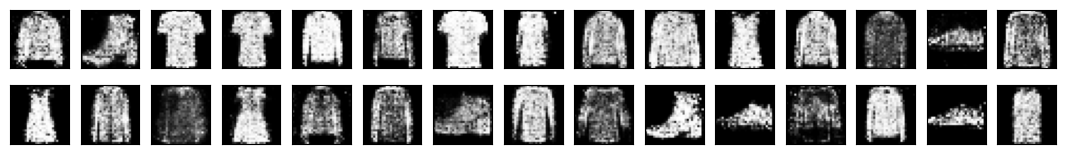

In [8]:
with torch.no_grad():
    fake_img = net_G_img(torch.randn(30, 100))
d2l.show_images(fake_img.reshape(30, 28, 28), 2, 15, scale=0.9, cmap='gray');

We also plot the per-epoch critic and generator losses in `history_img` against
the reference levels $2\log 2$ and $\log 2$:

In [ ]:
epochs = list(range(1, len(history_img) + 1))
fig, axes = d2l.plt.subplots(1, 2, figsize=(9, 3), sharex=True)
for ax, loss, ref, name, ref_name, fmt in zip(
        axes, history_img.T, (2 * math.log(2), math.log(2)),
        ('critic', 'generator'), ('2 log 2', 'log 2'), ('C0-', 'C1--')):
    d2l.plot(epochs, [loss, [ref] * len(epochs)], 'epoch', f'{name} loss',
             legend=[name, ref_name], fmts=(fmt, 'k:'), axes=ax)
fig.tight_layout()

The generated images capture recognizable garment silhouettes (shirts, trousers, shoes, bags), though with grainy pixel noise because an MLP lacks the spatial inductive bias of convolutions. Notice that even after 20 epochs, the discriminator loss ($\sim 1.05$) remains below its equilibrium value $2\log 2 \approx 1.39$ and the generator loss ($\sim 1.4$) above $\log 2 \approx 0.69$. Unlike the 2D Gaussian setting, loss curves alone on images cannot distinguish imperfect generation from discriminator overfitting (Exercise 6) or reveal whether all garment categories are covered equally (Exercise 4).

## Summary

A generative adversarial network trains an implicit generator $x' = G(z)$ without an explicit likelihood by pairing it with a discriminator (or critic) $D$ that separates real data $x \sim p$ from generated samples $x' \sim q$. Under binary log loss, the optimal discriminator logit recovers the log density ratio $D^\star(x) = \lambda(x) = \log(p(x)/q(x))$, and the optimal value function reduces to $\max_D V(D) = 2\,\mathrm{JS}(p, q) - 2\log 2$, where $\mathrm{JS}(p, q) = I(x; y) \in [0, \log 2]$ is the mutual information between a sample from $m = (p + q)/2$ and its source label. When generated samples are confidently rejected ($D(x') \ll 0$), the literal minimax generator weight $w_{\textrm{sat}}(x') = \sigma(D(x'))$ vanishes exponentially, whereas the non-saturating generator loss $-\mathbb{E}[\log \sigma(D(G(z)))]$ maintains near-unit weight $w_{\textrm{ns}}(x') = \sigma(-D(x')) \approx 1$. Against an optimal discriminator, the non-saturating loss descends $2\,D_{\textrm{KL}}(m \,\|\, p)$, which heavily penalizes out-of-support samples while assigning only a bounded penalty to dropped modes.

## Exercises

1. **Excess loss and the additive constant.** Let $\eta = p / (p + q)$ and let $D_{\textrm{b}}(a \,\|\, u)$ be the KL divergence between Bernoulli distributions with parameters $a$ and $u$.
    1. Show that every critic satisfies $V(D^\star) - V(D) = 2\, \mathbb{E}_{m}\big[D_{\textrm{b}}(\eta \,\|\, \sigma(D))\big]$, so that $D^\star$ is the unique maximizer of the equation up to $m$-null sets.
    1. Conclude that $V(D^\star + b) < V(D^\star)$ for every constant $b \neq 0$.
    1. Expand to second order in $b$ to show

       $$V(D^\star + b) - V(D^\star) = -\frac{b^2}{2} \int \frac{p q}{p + q}\, dx + O(b^3),$$

       with coefficient in $[0, \tfrac12]$. When $p$ and $q$ are nearly disjoint, how tightly do finite samples pin down the additive constant of $D$?

1. **Supports of measure zero.**
    1. A generator $G(z) = z v + \mu_q$ with a 1D latent $z \in \mathbb{R}$ places its samples on a line in $\mathbb{R}^2$. Show that $\mathrm{JS}(p, q) = \log 2$ against the 2D Gaussian data distribution $p = \mathcal{N}(\mu_p, A^\top A)$ for every $v$ and $\mu_q$.
    1. Show that $\mathrm{JS}(\hat p, q) = \log 2$ for the empirical distribution $\hat p$ of the 1,000 training points and every continuous density $q$ (including $q = p$).
    1. For a $\kappa$-Lipschitz critic $D$, use Kantorovich–Rubinstein duality (that section) to show that replacing $p$ by $\hat p$ in the equation changes $V(D)$ by at most $\kappa\, W_1(\hat p, p)$. Why does restricting the Lipschitz constant make training on empirical samples informative?

1. [code] **Saturating critic activations.** ● Replace the leaky-ReLU activations in `make_nets` with $\tanh$ units and hidden widths of 5 and 3.
    1. Rerun the non-saturating arm of that section for five seeds and record the final $D_{\textrm{KL}}(q \,\|\, p)$ and critic loss.
    1. For a stalled run, inspect the hidden activations and $\|\nabla_x D(x)\|$ at real and generated samples. Why does saturating the critic's hidden units prevent the non-saturating generator loss from recovering?
    1. Both a converged generator ($q = p$) and a constant critic ($D(x) = 0$) yield a critic loss of $2\log 2$. Which diagnostic in this section distinguishes the two?

1. [code] **Class coverage of the Fashion-MNIST generator.** ●
    1. Train LeNet (that section) on Fashion-MNIST, classify 1,000 samples from `net_G_img`, and compare the predicted class histogram against the uniform data distribution.
    1. Repeat for generators trained for 5 and 40 epochs. Does longer training make the class distribution more uniform?
    1. How does forced classification into 10 classes bias the histogram when some generated images are blurry or ambiguous? Relate your findings to mode dropping (that section).

1. **Generator weights and their divergences.** ●● A generator loss $\mathbb{E}_z[g(D(G(z)))]$ with fixed critic $D$ has gradient $-\mathbb{E}_z[w(D)\, \nabla_\theta D(G(z))]$ where $w = -g'$. Assume $D$ is held at the optimal log density ratio $\lambda = \log(p / q_{\theta_0})$ for the current generator $q_{\theta_0}$, and write $\rho = e^D = p / q_{\theta_0}$.
    1. Using $\int \nabla_\theta q_\theta = 0$, show that the unweighted loss $\mathbb{E}_z[-D(G(z))]$ ($w = 1$) has gradient $\nabla_\theta D_{\textrm{KL}}(q_\theta \,\|\, p)$ at $\theta = \theta_0$.
    1. For the $f$-divergence $D_f(p \,\|\, q_\theta) = \mathbb{E}_{q_\theta}[f(p/q_\theta)]$ (that section), show that $\nabla_\theta D_f\big|_{\theta_0} = -\mathbb{E}_z\big[\rho^2 f''(\rho)\, \nabla_\theta D(G(z))\big]$, so a weight function $w$ corresponds to the $f$-divergence satisfying $\rho^2 f''(\rho) = w(\log \rho)$.
    1. Identify the divergences corresponding to $w_{\textrm{sat}}$, $w = 1$, $w(t) = e^t$ [@Goodfellow.2016], and $w_{\textrm{ns}}$ (Theorem 2.5 of @Arjovsky.Bottou.2017).
    1. Use the equation to evaluate $2\,D_{\textrm{KL}}(m \,\|\, p)$ when $p$ has $K$ equal disjoint modes and $q$ covers only one of them, and compare its growth in $K$ with $D_{\textrm{KL}}(q \,\|\, p) = \log K$.

   *Adapted from Stefano Ermon and Aditya Grover's [CS236: Deep Generative Models](https://cs236.stanford.edu).*

1. [extended] **Finite samples and critic capacity.** ●● When the sample size exceeds the number of critic parameters by a factor of $\tilde O(1/\epsilon^2)$, the empirical critic value concentrates within $\epsilon$ of its population value [@Arora.Ge.Liang.ea.2017]. Fix the generator to the true data distribution ($G(z) = z A + \mu_p$, so $q = p$).
    1. Train 2-hidden-layer critics of width 4, 16, 128, and 1,024 on $n \in \{100, 1000, 10000\}$ fixed training points from $p$ (Adam at $10^{-3}$, 4,000 steps of batch size 256). Plot the generalization gap between the training loss and the population loss on fresh draws against parameter count.
    1. The Fashion-MNIST critic in that section has $\sim 530{,}000$ parameters and trains on 60,000 images. Design and run a test using the Fashion-MNIST test set to check whether its sub-$2\log 2$ loss reflects memorization of the training set or genuine discrepancy between $p$ and $q$.

[Discussions](https://d2l.discourse.group/t/36808)